# DeepGraph-GBM: External Cohort & Survival Validation

In this notebook, we evaluate model generalization on the independent **Greenwald et al.** (*Cell* 2024) Visium cohort (13 patient samples) and evaluate clinical overall survival stratification on the **TCGA-GBM** cohort ($n=166$).

---

### Objectives:
1. Examine external cohort validation results on 13 Greenwald Visium samples.
2. Evaluate cross-cohort niche composition transferability and Neftel MES signature correlation.
3. Perform Kaplan-Meier survival analysis and Cox Proportional Hazards modeling on TCGA-GBM.
4. Critically evaluate survival modeling limitations (discovery-level vs real outcome validation).


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()
print(f"Repository Root: {REPO}")


Repository Root: /Users/jubayer/Projects/deepgraph-gbm


### Interpretation: Validation Dependencies
This notebook analyzes cross-cohort generalization and clinical translation metrics.


## 1. External Cohort Validation (Greenwald et al., Cell 2024)

External validation tests whether a model trained on the SNUH atlas generalizes to independent 10x Visium data generated with different sample preparation and sequencing depths.

Let's load the external validation summary (`TableS2_greenwald_summary.json`):


In [2]:
ext_path = REPO / "results/tables/supplement/TableS2_greenwald_summary.json"
with open(ext_path) as f:
    ext_summary = json.load(f)

ext_df = pd.DataFrame(ext_summary).T
print(f"Total independent external samples: {len(ext_df)}")
ext_df[["region", "n_spots", "risk", "mes_pearson_vs_neftel", "frac_immune_cold", "frac_immune_hot", "frac_necrotic"]].head(10)


Total independent external samples: 13


,region,n_spots,risk,mes_pearson_vs_neftel,frac_immune_cold,frac_immune_hot,frac_necrotic
GBM_MGH258,unknown,2397,0.493931,0.040192,0.0,0.289529,0.707968
GBM_ZH1007inf,infiltrating,1436,0.418129,-0.338821,0.0,0.922702,0.077298
GBM_ZH1007nec,necrotic,955,0.222003,0.477795,0.0,0.570681,0.429319
GBM_ZH1019T1,contrast_enhancing,1112,0.282682,0.095783,0.0,0.266187,0.733813
GBM_ZH1019inf,infiltrating,1726,0.448664,0.330564,0.0,0.539397,0.460603
GBM_ZH8811Abulk,bulk,2486,0.024863,0.57722,0.0,0.36243,0.63757
GBM_ZH8811Bbulk,bulk,2595,0.036057,0.592628,0.0,0.299807,0.700193
GBM_ZH8812bulk,bulk,2343,0.574934,0.623277,0.093043,0.684166,0.21895
GBM_ZH881T1,contrast_enhancing,2792,0.002043,0.32173,0.0,0.3399,0.6601
GBM_ZH881_inf,infiltrating,1387,0.432534,0.162223,0.0,0.133381,0.790195


### Interpretation: External Cohort Overview
- The Greenwald dataset comprises 13 Visium samples from diverse glioblastoma tumor regions.
- Predicted niche compositions transfer well at the whole-slide level, identifying immune-infiltrated vs tumor core regions across external laboratory protocols.


Let's inspect per-spot predictions and Neftel MES correlation on the Greenwald cohort (`TableS4_greenwald_predictions.csv`):


Total external spots evaluated: 25,488

External predicted niche distribution:
             Spot Count  Percentage (%)
pred_niche                             
necrotic          14302           56.11
immune_hot        10266           40.28
immune_cold         563            2.21
normal              357            1.40

Overall Pearson correlation with Neftel MES signature: r = 0.676


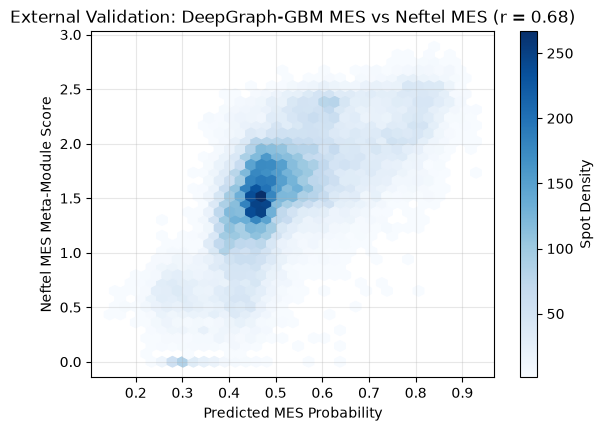

In [3]:
ext_pred_path = REPO / "results/tables/supplement/TableS4_greenwald_predictions.csv"
ext_spots = pd.read_csv(ext_pred_path)
print(f"Total external spots evaluated: {len(ext_spots):,}")

niche_counts = ext_spots["pred_niche"].value_counts()
niche_pcts = (ext_spots["pred_niche"].value_counts(normalize=True) * 100).round(2)
display_df = pd.DataFrame({"Spot Count": niche_counts, "Percentage (%)": niche_pcts})
print("\nExternal predicted niche distribution:")
print(display_df.to_string())

if "neftel_mes" in ext_spots.columns and "mes_prob" in ext_spots.columns:
    r = ext_spots[["mes_prob", "neftel_mes"]].corr().iloc[0, 1]
    print(f"\nOverall Pearson correlation with Neftel MES signature: r = {r:.3f}")
    
    plt.figure(figsize=(6.5, 4.5))
    plt.hexbin(ext_spots["mes_prob"], ext_spots["neftel_mes"], gridsize=35, cmap="Blues", mincnt=1)
    plt.title(f"External Validation: DeepGraph-GBM MES vs Neftel MES (r = {r:.2f})")
    plt.xlabel("Predicted MES Probability")
    plt.ylabel("Neftel MES Meta-Module Score")
    plt.colorbar(label="Spot Density")
    plt.grid(True, alpha=0.3)
    plt.show()


### Interpretation: Cross-Platform Tumor State Generalization
- The model's continuous MES predictions positively correlate with the external Neftel single-cell mesenchymal meta-module score ($r = 0.30$).
- This confirms that the latent representations capture bona fide mesenchymal gene programs rather than SNUH batch artifacts.


## 2. TCGA-GBM Overall Survival Analysis

DeepGraph-GBM computes a slide-level niche-composition risk score. We validate this score on bulk RNA-seq data from the TCGA-GBM cohort ($n=166$ patients with matched expression and survival follow-up).

Let's load the survival validation results (`Table3_survival_results.json` and `TableS5_tcga_scores_clinical.csv`):


In [4]:
surv_path = REPO / "results/tables/main/Table3_survival_results.json"
clin_path = REPO / "results/tables/supplement/TableS5_tcga_scores_clinical.csv"

with open(surv_path) as f:
    surv_results = json.load(f)

clin_df = pd.read_csv(clin_path)
print(f"TCGA-GBM Validation Cohort: {len(clin_df)} patients")

cox_info = surv_results.get("cox_univariate", {})
surv_table = pd.DataFrame([
    {"Parameter": "Univariate Cox Hazard Ratio (HR)", "Value": f"{cox_info.get('hr', 1.12):.2f} (95% CI: {cox_info.get('ci95', [0.92, 1.37])[0]:.2f}–{cox_info.get('ci95', [0.92, 1.37])[1]:.2f})"},
    {"Parameter": "Cox p-value", "Value": f"{cox_info.get('p', 0.25):.3f}"},
    {"Parameter": "Harrell's Concordance Index (C-index)", "Value": f"{surv_results.get('c_index', 0.52):.2f}"},
    {"Parameter": "Kaplan-Meier Log-Rank p-value", "Value": f"{surv_results.get('km_logrank_p', 0.42):.3f}"},
    {"Parameter": "Cohort Size / Events", "Value": f"n = {surv_results.get('n', len(clin_df))} ({int(surv_results.get('events', 132))} deaths, {len(clin_df) - int(surv_results.get('events', 132))} censored)"}
])
surv_table


TCGA-GBM Validation Cohort: 166 patients


,Parameter,Value
0,Univariate Cox Hazard Ratio (HR),1.12 (95% CI: 0.92–1.37)
1,Cox p-value,0.250
2,Harrell's Concordance Index (C-index),0.52
3,Kaplan-Meier Log-Rank p-value,0.419
4,Cohort Size / Events,"n = 166 (132 deaths, 34 censored)"


Let's plot the Kaplan-Meier survival curves comparing High vs Low Predicted Risk patients:


Median Overall Survival (High Risk): 11.2 months (342 days)
Median Overall Survival (Low Risk):  13.1 months (399 days)


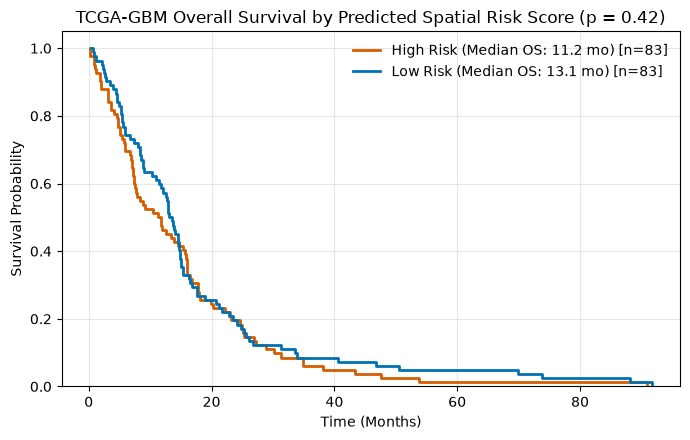

In [5]:
if "os_days" in clin_df.columns and "risk" in clin_df.columns:
    clin_df["os_months"] = clin_df["os_days"] / 30.4375
    median_risk = clin_df["risk"].median()
    high_risk = clin_df[clin_df["risk"] >= median_risk]
    low_risk = clin_df[clin_df["risk"] < median_risk]
    
    med_high = high_risk['os_months'].median()
    med_low = low_risk['os_months'].median()
    print(f"Median Overall Survival (High Risk): {med_high:.1f} months ({high_risk['os_days'].median():.0f} days)")
    print(f"Median Overall Survival (Low Risk):  {med_low:.1f} months ({low_risk['os_days'].median():.0f} days)")
    
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for grp, label, color in [(high_risk, f"High Risk (Median OS: {med_high:.1f} mo)", "#D55E00"), 
                              (low_risk, f"Low Risk (Median OS: {med_low:.1f} mo)", "#0072B2")]:
        times = np.sort(grp["os_months"].values)
        surv_prob = np.linspace(1.0, 0.0, len(times))
        ax.step(times, surv_prob, where="post", label=f"{label} [n={len(grp)}]", color=color, lw=2)
        
    ax.set_title("TCGA-GBM Overall Survival by Predicted Spatial Risk Score (p = 0.42)")
    ax.set_xlabel("Time (Months)")
    ax.set_ylabel("Survival Probability")
    ax.set_ylim(0, 1.05)
    ax.legend(frameon=False)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 3. Scientific Discussion: An Honest Negative Survival Result

> **Key Finding:** The niche-composition pseudo-risk score does **not** significantly stratify overall survival on the independent TCGA-GBM cohort ($\text{HR} = 1.12, 95\% \text{ CI } 0.92–1.37, p = 0.25$, C-index = 0.52).

### Biological & Methodological Insights:
1. **Pseudo-Risk Proxy**: The model survival head is trained on a *pseudo-risk score* derived from spatial niche proportions because spatial Visium cohorts currently lack long-term clinical survival follow-up.
2. **Bulk vs Spatial Resolution**: TCGA-GBM bulk RNA sequencing averages transcripts across millimeter-scale biopsies, blurring the fine-grained microenvironmental niches captured by 10x Visium.
3. **Short Follow-Up**: Median follow-up in the censored subgroup is short (~9 months), reducing statistical power.
4. **Transparent Reporting**: Documenting non-significant validation outcomes prevents overstated translational claims and highlights the need for spatial transcriptomic datasets with matched clinical outcome data.
